# Análise Exploratória de Dados de E-commerce

## Objetivo
Explorar um conjunto de dados de produtos de moda vendidos em um e-commerce para entender como **preço, desconto, nota, número de avaliações e quantidade vendida** se relacionam, e quais são as características do catálogo (marcas, gêneros e temporadas).

## Sobre os dados
- **Arquivo:** `ecommerce_estatistica.csv`
- **Tamanho:** 295 produtos, sem valores nulos
- **Variáveis numéricas principais:** `Nota`, `N_Avaliações`, `Desconto`, `Preço` e `Qtd_Vendidos_Cod`
- **Variáveis categóricas principais:** `Marca`, `Material`, `Gênero` e `Temporada`

## Roteiro da análise
Começamos pelo **mapa de calor**, que mostra de uma só vez quais variáveis numéricas andam juntas. A partir dele, defini os demais gráficos, nesta ordem:

1. **Mapa de calor:** visão geral das correlações entre as variáveis numéricas.
2. **Dispersão:** a relação mais forte do mapa realmente vale para todos os produtos?
3. **Regressão:** as relações fracas têm alguma tendência?
4. **Histograma:** como os preços se distribuem?
5. **Barras:** quais marcas têm mais produtos no catálogo?
6. **Pizza:** como os produtos se dividem por temporada?
7. **Densidade:** os descontos se distribuem de forma diferente entre os gêneros?

## Bibliotecas utilizadas
`pandas`, `matplotlib`, `seaborn`, `pathlib` e `scipy`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração para mostrar os dados do DataFrame completo
pd.set_option('display.max_columns', None)    # mostra todas as colunas
pd.set_option('display.max_colwidth', 50)     # limita o tamanho dos textos longos (Review1, Review2...)


# Carregar o arquivo CSV e verificar o cabeçalho do DataFrame
df = pd.read_csv('ecommerce_estatistica.csv')
print(df.head())
df.dtypes


   Unnamed: 0                                             Título  Nota  \
0           1  Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...   4.5   
1           2  Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...   4.7   
2           3  Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...   4.6   
3           4  Kit 3 Short Jeans Feminino Cintura Alta Barato...   4.4   
4           5  Blusa + Calça Térmica Treino Futebol Criança I...   4.7   

   N_Avaliações  Desconto            Marca         Material  \
0        3034.0      18.0             lupo          algodão   
1        5682.0      20.0            zorba          algodão   
2        1700.0      22.0             mash          algodão   
3         507.0       9.0     menina linda             jean   
4          58.0       5.0  roupa zero grau  termico unissex   

                Gênero        Temporada  \
0            Masculino   outono/inverno   
1            Masculino     não definido   
2            Masculino  primavera/verão   
3   

Unnamed: 0               int64
Título                     str
Nota                   float64
N_Avaliações           float64
Desconto               float64
Marca                      str
Material                   str
Gênero                     str
Temporada                  str
Review1                    str
Review2                    str
Review3                    str
Qtd_Vendidos               str
Preço                  float64
Nota_MinMax            float64
N_Avaliações_MinMax    float64
Desconto_MinMax        float64
Preço_MinMax           float64
Marca_Cod                int64
Material_Cod             int64
Temporada_Cod            int64
Qtd_Vendidos_Cod       float64
Marca_Freq             float64
Material_Freq          float64
dtype: object

In [2]:
# Visão geral dos dados
print(f'Produtos: {df.shape[0]} | Colunas: {df.shape[1]} | Valores nulos: {df.isna().sum().sum()}')
print(f"N_Avaliações: mediana {df['N_Avaliações'].median():.0f} | máximo {df['N_Avaliações'].max():.0f} | produtos acima de 5 mil: {(df['N_Avaliações'] > 5000).sum()}")

Produtos: 295 | Colunas: 24 | Valores nulos: 0
N_Avaliações: mediana 77 | máximo 9077 | produtos acima de 5 mil: 6


In [3]:
from pathlib import Path

# Cria a pasta 'graficos' (se ainda não existir) para salvar as imagens dos gráficos
# exist_ok=True -> não dá erro caso a pasta já exista
Path('graficos').mkdir(exist_ok=True)

## Mapa de calor: escolha das variáveis

O conjunto de dados tem 24 colunas, mas usei apenas 5 no mapa de calor: `Nota`, `N_Avaliações`, `Desconto`, `Preço` e `Qtd_Vendidos_Cod`. São as únicas que medem algo numérico do produto e, por isso, podem ser comparadas entre si.

**O que deixei de fora e por quê**
- **Colunas de texto** (`Título`, `Marca`, `Material`, `Gênero`, `Temporada`, `Review1-3`, `Qtd_Vendidos`): correlação exige variáveis numéricas.
- **`Unnamed: 0`:** é só o índice da linha.
- **Colunas `_MinMax`:** são versões normalizadas das originais, com correlação 1 com elas (conferido na célula abaixo), ou seja, informação repetida.
- **Colunas `_Cod` e `_Freq`:** vêm de variáveis categóricas, e os números não têm ordem nem magnitude real, então suas correlações não são interpretáveis.

**Observação:** `Qtd_Vendidos_Cod` é uma aproximação, pois vem de faixas como "+100" e "+1000".

In [4]:
# Conferência da correlação entre as colunas originais e as colunas normalizadas (MinMax)
for coluna in ['Nota', 'N_Avaliações', 'Desconto', 'Preço']:
    print(f'{coluna} x {coluna}_MinMax: {df[coluna].corr(df[coluna + "_MinMax"]):.2f}')

Nota x Nota_MinMax: 1.00
N_Avaliações x N_Avaliações_MinMax: 1.00
Desconto x Desconto_MinMax: 1.00
Preço x Preço_MinMax: 1.00


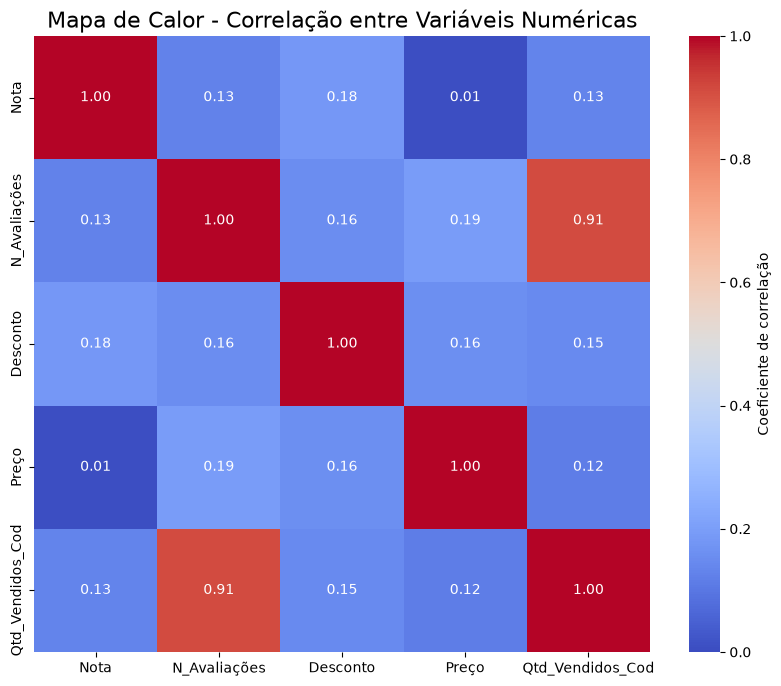

In [5]:
# Novo dataframe com as colunas numéricas para análise de correlação
df_corr = df[['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos_Cod']].corr()

# Mapa de calor para verificar a correlação entre as variáveis numéricas
plt.figure(figsize = (10, 8))

# annotation = True -> mostra os valores da correlação no mapa de calor
# cmap = 'coolwarm' -> define a paleta de cores do mapa de calor
# fmt = '.2f' -> define o formato dos valores da correlação (2 casas decimais)
# square = True -> define o formato do mapa de calor como quadrado
# vmin = 0 e vmax = 1 -> define o intervalo da legenda do mapa de calor
# cbar_kws = {'label': 'Coeficiente de correlação'} -> define o rótulo da legenda do mapa de calor
sns.heatmap(
    df_corr, 
    annot = True, 
    cmap = 'coolwarm', 
    fmt = '.2f',
    square=True,
    vmin=0,
    vmax=1,
    cbar_kws={'label': 'Coeficiente de correlação'}
)

plt.title('Mapa de Calor - Correlação entre Variáveis Numéricas', fontsize = 16)

# Salvar o gráfico em arquivo PNG
# dpi = 150 -> define a resolução do gráfico em pontos por polegada
# bbox_inches = 'tight' -> ajusta o tamanho do gráfico para que não haja cortes
plt.savefig('graficos/mapa_calor_correlacao.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretação do mapa de calor

A correlação mais forte é entre **`N_Avaliações` e `Qtd_Vendidos_Cod` (0,91)**: produtos mais avaliados tendem a vender mais. Como as avaliações vêm de quem comprou, é natural que as duas cresçam juntas; isso não significa que as avaliações causem as vendas.

Todas as outras correlações são **fracas (entre 0,01 e 0,19)**. Preço e nota quase não se relacionam (0,01), então produtos mais caros não recebem notas melhores nem piores. O desconto tem correlação baixa com todas as variáveis (0,15 a 0,18) e, nesses dados, não parece explicar vendas nem satisfação.

Não há correlações negativas: a legenda foi fixada entre 0 e 1, então o azul indica correlação próxima de zero, e não relação inversa.

**Um cuidado:** a correlação de Pearson é sensível a valores extremos, e `N_Avaliações` é muito assimétrica (mediana de 77, mas 6 produtos passam de 5 mil avaliações e o maior chega a 9.077). A dispersão a seguir verifica se o 0,91 vale para a maioria dos produtos ou é puxado por poucos.

In [6]:
# Mostrar estatísticas descritivas da coluna N_Avaliações agrupadas por Qtd_Vendidos_Cod
print(df.groupby('Qtd_Vendidos_Cod')['N_Avaliações'].agg(['count', 'median', 'min', 'max']))

                  count  median     min     max
Qtd_Vendidos_Cod                               
5.0                   2     7.0     6.0     8.0
25.0                 18     6.5     3.0    18.0
50.0                 26     9.0     4.0    26.0
100.0               104    27.0     7.0   104.0
1000.0               97   227.0    30.0   779.0
10000.0              41  1700.0   303.0  3037.0
50000.0               7  5688.0  2363.0  9077.0


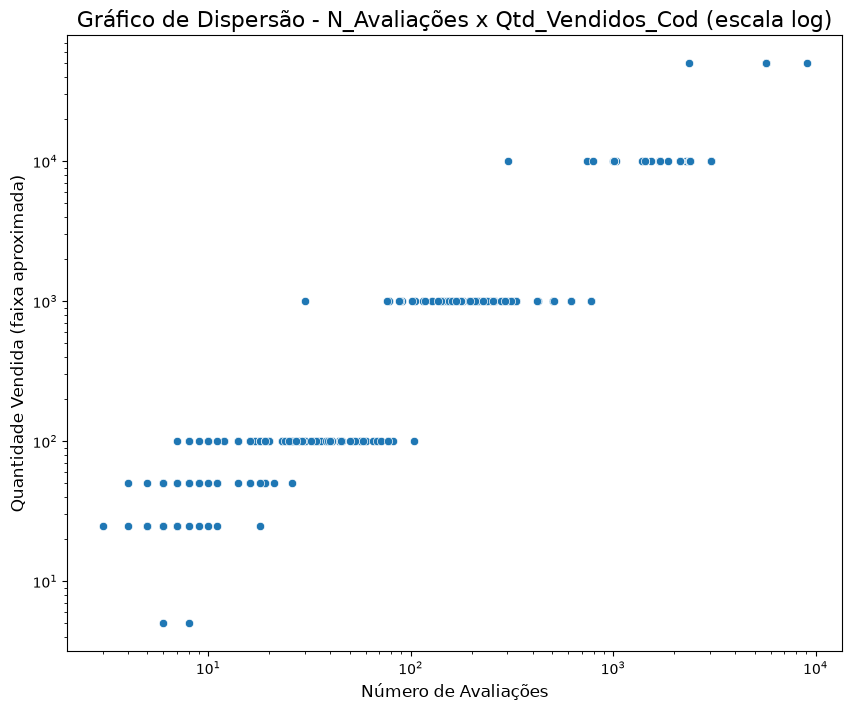

In [7]:
# Gráfico de dispersão entre N_Avaliações e Qtd_Vendidos_Cod
plt.figure(figsize = (10, 8))
sns.scatterplot(x='N_Avaliações', y='Qtd_Vendidos_Cod', data=df)

# Configuração de escala logarítmica para melhor visualização dos dados
plt.xscale('log')
plt.yscale('log')

# Título e rótulos dos eixos
plt.title('Gráfico de Dispersão - N_Avaliações x Qtd_Vendidos_Cod (escala log)', fontsize = 16)
plt.xlabel('Número de Avaliações', fontsize = 12)
plt.ylabel('Quantidade Vendida (faixa aproximada)', fontsize = 12)

# Salvar o gráfico em arquivo PNG
# dpi = 150 -> define a resolução do gráfico em pontos por polegada
# bbox_inches = 'tight' -> ajusta o tamanho do gráfico para que não haja cortes
plt.savefig('graficos/grafico_dispersao_n_avaliacoes_x_qtd_vendidos_cod.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Teste: a correlação depende dos produtos mais vendidos (faixa "+50mil")?
sem_extremos = df[df['Qtd_Vendidos_Cod'] < 50000]

corr_todos = df['N_Avaliações'].corr(df['Qtd_Vendidos_Cod'])
corr_sem_extremos = sem_extremos['N_Avaliações'].corr(sem_extremos['Qtd_Vendidos_Cod'])

print(f'Produtos na faixa "+50mil": {len(df) - len(sem_extremos)}')
print(f'Correlação com todos os produtos ({len(df)}): {corr_todos:.2f}')
print(f'Correlação sem a faixa "+50mil" ({len(sem_extremos)}): {corr_sem_extremos:.2f}')

Produtos na faixa "+50mil": 7
Correlação com todos os produtos (295): 0.91
Correlação sem a faixa "+50mil" (288): 0.90


### Interpretação do gráfico de dispersão

Usei **escala logarítmica** porque `N_Avaliações` é muito assimétrica: em escala linear, a maioria dos produtos ficava amontoada no canto inferior esquerdo, sem dar para distinguir um do outro. Na escala log, cada marca do eixo multiplica o valor por 10, então a leitura é em "ordens de grandeza". A escala muda só a visualização; a correlação de 0,91 continua calculada com os valores originais.

Os pontos formam **faixas horizontais** porque `Qtd_Vendidos_Cod` vem de categorias ("+100", "+1000", "+10mil"...) e só assume 7 valores. É uma aproximação, não a venda exata.

A **tendência crescente aparece no catálogo todo**: quanto maior a faixa de vendas, mais avaliações (a mediana é de 27 na faixa "+100", 227 na "+1000", 1.700 na "+10mil" e 5.688 na "+50mil"). As faixas vizinhas se sobrepõem um pouco, mas cada uma se concentra numa região diferente do eixo x.

**Teste dos valores extremos:** os 7 produtos da faixa "+50mil" pareciam sustentar a correlação de 0,91. Sem eles, ela cai só para 0,90, então a relação não depende deles.

**Conclusão:** avaliações e vendas crescem juntas ao longo do catálogo. Como as avaliações vêm de quem comprou, isso não indica que uma cause a outra.

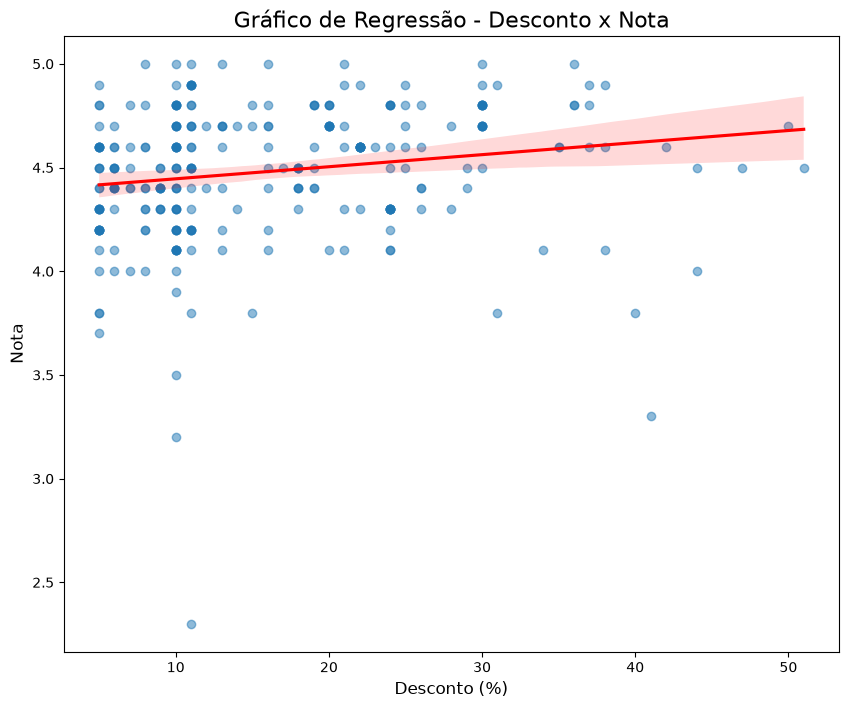

In [9]:
# Gráfico de regressão entre Descontos e Nota
plt.figure(figsize = (10, 8))

# scatter_kws={'alpha': 0.5} -> define a transparência dos pontos do gráfico de dispersão
# line_kws={'color': 'red'} -> define a cor da linha de regressão
sns.regplot(
    x='Desconto', y='Nota', data=df,
    scatter_kws={'alpha': 0.5},      
    line_kws={'color': 'red'}       
)

# Título e rótulos dos eixos
plt.title('Gráfico de Regressão - Desconto x Nota', fontsize = 16)
plt.xlabel('Desconto (%)', fontsize = 12)
plt.ylabel('Nota', fontsize = 12)

# Salvar o gráfico em arquivo PNG
# dpi = 150 -> define a resolução do gráfico em pontos por polegada
# bbox_inches = 'tight' -> ajusta o tamanho do gráfico para que não haja cortes
plt.savefig('graficos/grafico_regressao_desconto_x_nota.png', dpi=150, bbox_inches='tight')
plt.show()


In [10]:
# Calcular a inclinação da linha de regressão e o R² (coeficiente de determinação) entre Desconto e Nota
from scipy import stats

r = stats.linregress(df['Desconto'], df['Nota'])
print(f'Inclinação: {r.slope:.4f}  (por 10 pontos de desconto: {r.slope*10:.2f})')
print(f'R²: {r.rvalue**2:.3f} | p-valor: {r.pvalue:.4f}')
print(f'Produtos com desconto acima de 35%: {(df["Desconto"] > 35).sum()} de {len(df)}')

Inclinação: 0.0058  (por 10 pontos de desconto: 0.06)
R²: 0.032 | p-valor: 0.0019
Produtos com desconto acima de 35%: 17 de 295


### Interpretação do gráfico de regressão

A relação entre **desconto e nota é fraca** (correlação de 0,18), o que já aparecia no mapa de calor e se confirma aqui: a reta sobe só um pouco, cerca de **0,06 ponto de nota a cada 10 pontos percentuais de desconto**.

O desconto explica apenas cerca de **3% da variação da nota** (R² = 0,03), e os pontos ficam muito espalhados em torno da reta, então a nota depende de outros fatores. A faixa de confiança (em rosa) alarga nos descontos altos porque há poucos produtos ali (17 dos 295 têm desconto acima de 35%), e a tendência fica menos segura.

Correlação não é causalidade: os dados não indicam que dar desconto melhora a nota.

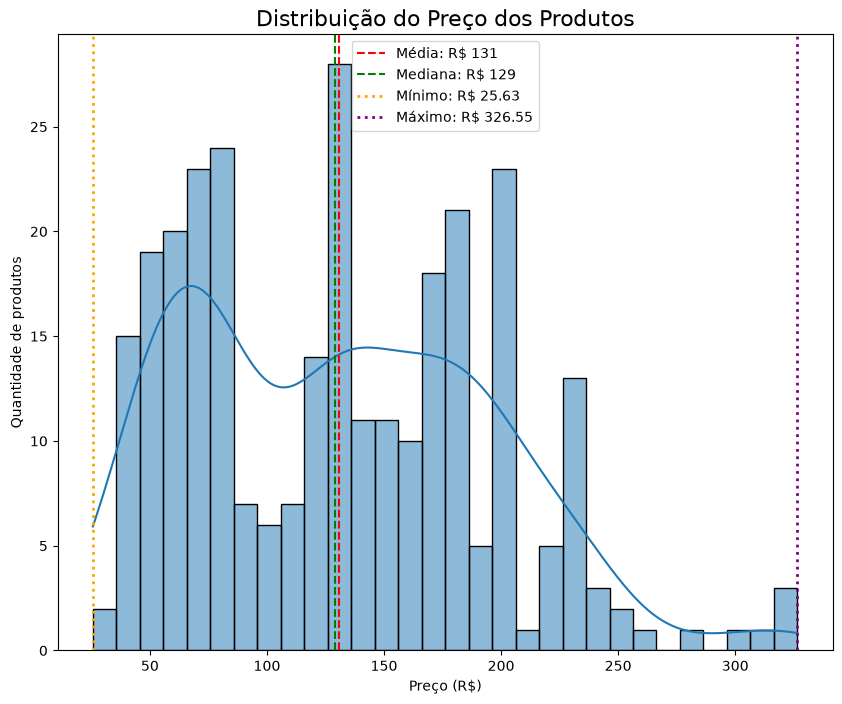

In [11]:
# Gráfico de histograma do Preço dos produtos
plt.figure(figsize=(10, 8))

# bins=30 -> define o número de intervalos do histograma
# kde=True -> adiciona a curva de densidade ao histograma
sns.histplot(data=df, x='Preço', bins=30, kde=True)

# Adiciona uma linha vertical indicando a média do Preço
# linestyle='--' -> define o estilo da linha como tracejada
# label=f"Média: R$ {df['Preço'].mean():.0f}" -> define o rótulo da linha com a média do Preço formatada para 0 casas decimais
plt.axvline(df['Preço'].mean(), color='red', linestyle='--', label=f"Média: R$ {df['Preço'].mean():.0f}")

# Adiciona uma linha vertical indicando a mediana do Preço
# label=f"Mediana: R$ {df['Preço'].median():.0f}" -> define o rótulo da linha com a mediana do Preço formatada para 0 casas decimais
plt.axvline(df['Preço'].median(), color='green', linestyle='--', label=f"Mediana: R$ {df['Preço'].median():.0f}")


# Adiciona ao gráfico o menor e maior preço
plt.axvline(df['Preço'].min(), color='orange', linestyle=':', linewidth=2, label=f"Mínimo: R$ {df['Preço'].min():.2f}")
plt.axvline(df['Preço'].max(), color='purple', linestyle=':', linewidth=2, label=f"Máximo: R$ {df['Preço'].max():.2f}")


# Adiciona a legenda para as linhas de média, mediana, mínimo e máximo
plt.legend()


# Título e rótulos dos eixos
plt.title('Distribuição do Preço dos Produtos', fontsize=16)
plt.xlabel('Preço (R$)')
plt.ylabel('Quantidade de produtos')

# Salvar o gráfico em arquivo PNG
# dpi = 150 -> define a resolução do gráfico em pontos por polegada
# bbox_inches = 'tight' -> ajusta o tamanho do gráfico para que não haja cortes
plt.savefig('graficos/histograma_preco.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Conferência de alguns números para análise do gráfico
df_sem_dup = df.drop(columns='Unnamed: 0').drop_duplicates()   # sem a coluna de índice, que é diferente em toda linha

print(f"Linhas repetidas: {len(df) - len(df_sem_dup)}")
print(f"Produtos até R$ 100: {(df['Preço'] <= 100).sum()} de {len(df)}")
print(f"Produtos acima de R$ 250: {(df['Preço'] > 250).sum()}")
print(f"Sem duplicatas: média R$ {df_sem_dup['Preço'].mean():.0f} | mediana R$ {df_sem_dup['Preço'].median():.0f}")
print(f"Média: R$ {df['Preço'].mean():.2f} | mediana: R$ {df['Preço'].median():.2f}")

Linhas repetidas: 57
Produtos até R$ 100: 116 de 295
Produtos acima de R$ 250: 7
Sem duplicatas: média R$ 127 | mediana R$ 126
Média: R$ 130.84 | mediana: R$ 129.21


### Interpretação do histograma de Preço

Os preços vão de **R$ 25,63 a R$ 326,55**, e a maior parte dos produtos é barata: 116 dos 295 custam até R$ 100, e só 7 passam de R$ 250 (cauda longa à direita).

A distribuição **não tem formato de sino**: há mais de uma concentração, perto de R$ 60–80 e entre R$ 130 e R$ 200, o que sugere grupos de produtos em faixas de preço diferentes. Média (R$ 130,84) e mediana (R$ 129,21) são quase iguais, mas, como há vários grupos, **um preço médio não representa bem o catálogo**.

**Observação:** os dados têm 57 linhas repetidas, mantidas na análise. Sem elas, média e mediana quase não mudam (R$ 127 e R$ 126).

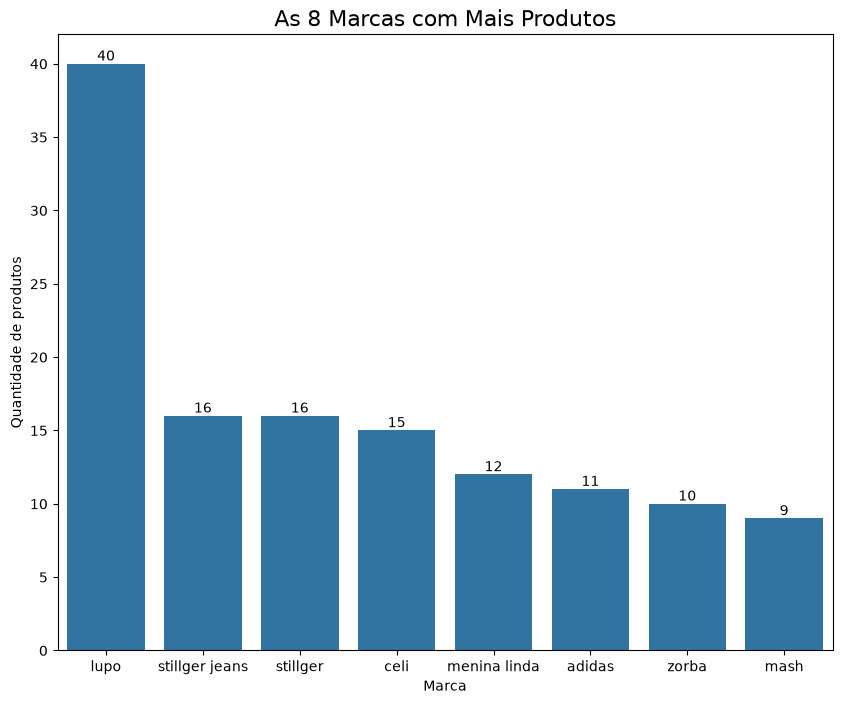

In [13]:
# Gráfico de barras marcas com mais produtos
# Selecionar as 8 marcas com mais produtos
top_marcas = df['Marca'].value_counts().head(8)

plt.figure(figsize=(10, 8))
ax = sns.barplot(x=top_marcas.index, y=top_marcas.values)
# ax.bar_label() -> adiciona os valores das barras no gráfico
# containers[0] -> seleciona o primeiro container do gráfico, que contém as barras
ax.bar_label(ax.containers[0])

plt.title('As 8 Marcas com Mais Produtos', fontsize=16)
plt.xlabel('Marca')
plt.ylabel('Quantidade de produtos')

# Salvar o gráfico em arquivo PNG
# dpi = 150 -> define a resolução do gráfico em pontos por polegada
# bbox_inches = 'tight' -> ajusta o tamanho do gráfico para que não haja cortes
plt.savefig('graficos/barras_marcas.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Conferência de alguns números importantes para análise do gráfico
contagem_marca = df['Marca'].value_counts()
top8 = contagem_marca.head(8)

# O f antes das aspas cria uma f-string: um texto em que o que está entre chaves {} é calculado 
# pelo Python e colocado no lugar. 
# Sem o f, as chaves seriam impressas literalmente.
print(f'Total de produtos: {len(df)}')
print(f'Marcas distintas: {df["Marca"].nunique()}')
print(f'Marcas com um único produto: {(contagem_marca == 1).sum()}')
print()
print(f'lupo: {contagem_marca["lupo"]} produtos ({contagem_marca["lupo"] / len(df):.1%} do catálogo)')
print(f'Segunda colocada ({top8.index[1]}): {top8.iloc[1]} -> lupo tem {top8.iloc[0] / top8.iloc[1]:.1f}x mais')
print(f'Top 8 somam: {top8.sum()} produtos ({top8.sum() / len(df):.1%})')
print()

# Efeito das linhas repetidas (a coluna de índice é removida, pois é diferente em toda linha)
df_sem_dup = df.drop(columns='Unnamed: 0').drop_duplicates()
comparacao = pd.DataFrame({
    'com_duplicatas': top8,
    'sem_duplicatas': df_sem_dup['Marca'].value_counts().reindex(top8.index)
})
print(f'Linhas repetidas: {len(df) - len(df_sem_dup)}')
print(comparacao)

Total de produtos: 295
Marcas distintas: 108
Marcas com um único produto: 75

lupo: 40 produtos (13.6% do catálogo)
Segunda colocada (stillger jeans): 16 -> lupo tem 2.5x mais
Top 8 somam: 129 produtos (43.7%)

Linhas repetidas: 57
                com_duplicatas  sem_duplicatas
Marca                                         
lupo                        40              26
stillger jeans              16              11
stillger                    16              12
celi                        15               3
menina linda                12               8
adidas                      11              10
zorba                       10               8
mash                         9               6


### Interpretação do gráfico de barras

A marca **lupo lidera com 40 produtos** (13,6% do catálogo), 2,5 vezes mais que a segunda colocada (empate entre "stillger" e "stillger jeans", com 16 cada). As demais marcas do gráfico ficam entre 9 e 16 produtos.

As 8 marcas mais frequentes somam 129 dos 295 produtos (43,7%). O resto está espalhado entre muitas marcas pequenas: são 108 no total, e 75 têm um único produto.

**Como tratei os dados**
- Mantive "stillger" e "stillger jeans" separadas, como aparecem no arquivo. Elas podem ser do mesmo vendedor; somadas, teriam 32 produtos, ainda atrás da lupo.
- Mantive as linhas repetidas, e elas afetam a contagem: a "celi" tem 15 produtos no arquivo, mas só 3 sem as repetições. A "lupo" segue em primeiro nos dois casos (40 e 26).

**Vale lembrar:** o gráfico conta produtos anunciados por marca, e não vendas.


In [15]:
# Conferir os produtos da temporada "2021" e verificar se há linhas repetidas
linhas_2021 = df[df['Temporada'] == '2021']
print(f'Produtos em "2021": {len(linhas_2021)} | títulos distintos: {linhas_2021["Título"].nunique()}')
print(linhas_2021['Título'].iloc[0])

Produtos em "2021": 8 | títulos distintos: 1
Kit 10 Cuecas Lupo Boxer Masculinas Atacado Box 523 Algodão


In [16]:
# Dicionário para agrupar as diferentes formas de informar a temporada em uma única categoria
mapa_temporada = {
    '2021': 'não definido',
    'primavera-verão outono-inverno': 'todas as estações',
    'primavera-verão - outono-inverno': 'todas as estações',
    'primavera/verão/outono/inverno': 'todas as estações',
}

# Novo dataframe com a coluna Temporada_Agrupada, 
# que substitui os valores da coluna Temporada pelos valores do dicionário mapa_temporada
df['Temporada_Agrupada'] = df['Temporada'].replace(mapa_temporada)

# Conferência de alguns números para análise do gráfico
# mul(100) -> multiplica os valores por 100 para obter porcentagens
# round(1) -> arredonda os valores para 1 casa decimal
print(df['Temporada_Agrupada'].value_counts(), '\n')
print(df['Temporada_Agrupada'].value_counts(normalize=True).mul(100).round(1))

Temporada_Agrupada
primavera/verão      133
outono/inverno        83
não definido          70
todas as estações      9
Name: count, dtype: int64 

Temporada_Agrupada
primavera/verão      45.1
outono/inverno       28.1
não definido         23.7
todas as estações     3.1
Name: proportion, dtype: float64


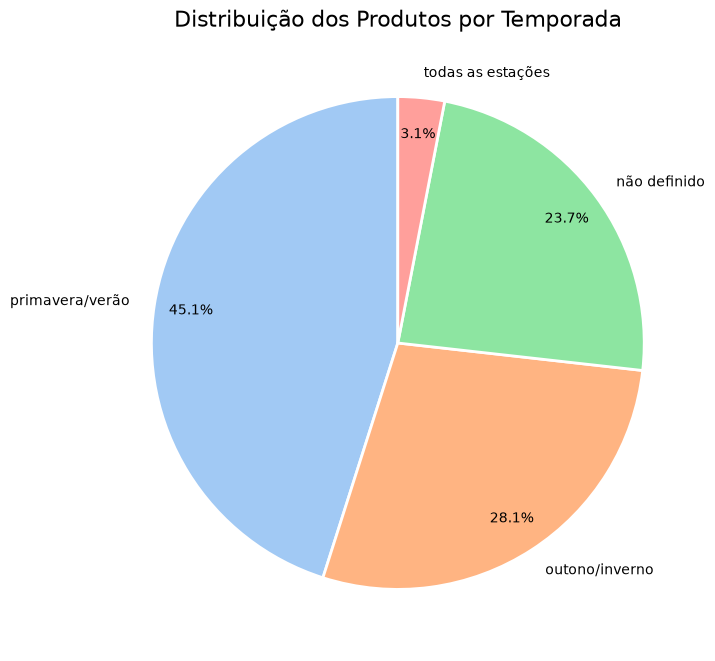

In [17]:
# Gráfico de pizza da distribuição das temporadas agrupadas
contagem_temporada = df['Temporada_Agrupada'].value_counts()

plt.figure(figsize=(10, 8))

# Configuração do gráfico de pizza
# autopct='%1.1f%%' -> define o formato dos valores das fatias (1 casa decimal)
# startangle=90 -> define o ângulo inicial do gráfico de pizza
# pctdistance=0.85 -> define a distância dos valores das fatias em relação ao centro do gráfico
# wedgeprops={'edgecolor': 'white', 'linewidth': 2} -> define a cor e a largura da borda das fatias
plt.pie(
    contagem_temporada,
    labels=contagem_temporada.index,
    colors=sns.color_palette('pastel'),
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.85,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 10}
)

plt.title('Distribuição dos Produtos por Temporada', fontsize=16)

plt.savefig('graficos/pizza_temporada.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# Conferência de alguns números para análise do gráfico
print(df['Temporada_Agrupada'].value_counts(), '\n')
print(df['Temporada_Agrupada'].value_counts(normalize=True).mul(100).round(1), '\n')


# Quantas vezes o primeiro é maior que o segundo
contagem_temporada = df['Temporada_Agrupada'].value_counts()

primeiro = contagem_temporada.iloc[0]
segundo = contagem_temporada.iloc[1]

print(f'Primeiro colocado ({contagem_temporada.index[0]}): {primeiro}')
print(f'Segundo colocado ({contagem_temporada.index[1]}): {segundo}')
print(f'{contagem_temporada.index[0]} tem {primeiro / segundo:.1f}x mais produtos que {contagem_temporada.index[1]}', '\n')


# Tirar as linhas repetidas (a coluna de índice é removida, pois é diferente em toda linha)
df_sem_dup = df.drop(columns='Unnamed: 0').drop_duplicates()
print('\nSem linhas repetidas:')
print(df_sem_dup['Temporada'].replace(mapa_temporada).value_counts(normalize=True).mul(100).round(1))

Temporada_Agrupada
primavera/verão      133
outono/inverno        83
não definido          70
todas as estações      9
Name: count, dtype: int64 

Temporada_Agrupada
primavera/verão      45.1
outono/inverno       28.1
não definido         23.7
todas as estações     3.1
Name: proportion, dtype: float64 

Primeiro colocado (primavera/verão): 133
Segundo colocado (outono/inverno): 83
primavera/verão tem 1.6x mais produtos que outono/inverno 


Sem linhas repetidas:
Temporada
primavera/verão      43.7
outono/inverno       31.9
não definido         20.6
todas as estações     3.8
Name: proportion, dtype: float64


### Interpretação do gráfico de pizza

O catálogo é puxado pela **primavera/verão**: são 133 dos 295 produtos (45,1%), cerca de 1,6 vez mais que outono/inverno, que tem 83 (28,1%). Juntas, as duas estações somam 73,2% dos produtos.

O que também chama atenção é que **quase 1 em cada 4 produtos não informa a temporada** (23,7%). Já os anunciados para "todas as estações" são raros: apenas 9, ou 3,1% do total.

**Como tratei os dados**
- A categoria "2021" tinha 8 produtos, todos o mesmo anúncio repetido. Como um ano não diz a estação, agrupei em "não definido". As três formas de escrever "todas as estações" também foram unificadas.
- Mantive as linhas repetidas na análise. Sem elas, as proporções mudam um pouco (primavera/verão vai para 43,7% e outono/inverno para 31,9%), mas primavera/verão continua sendo a mais frequente.

**Vale lembrar:** o gráfico conta produtos anunciados por temporada, e não vendas.

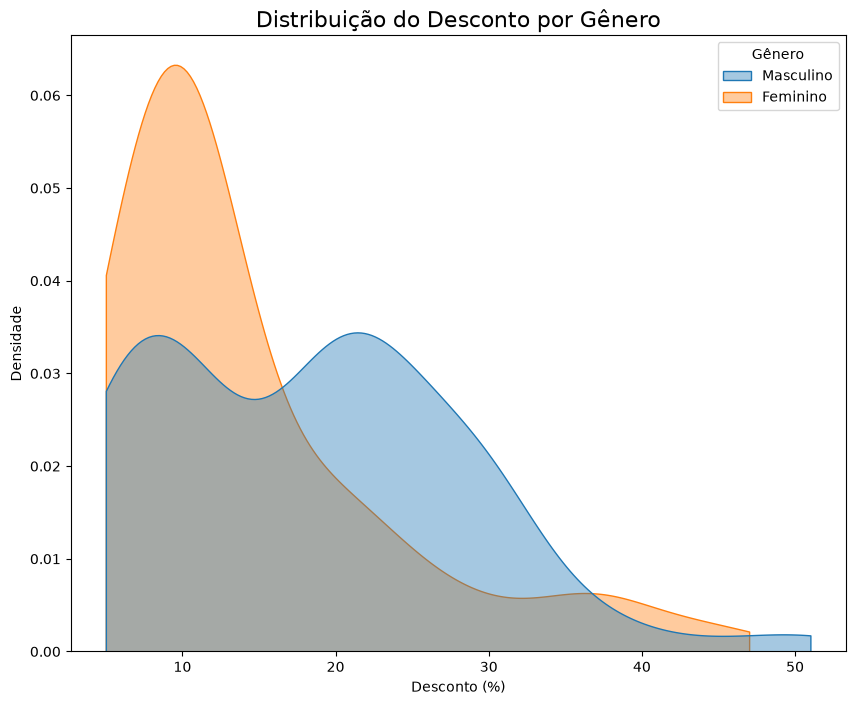

In [19]:
# Gráfico de densidade do Desconto por Gênero

# Novo dataframe com apenas os produtos com gênero Masculino ou Feminino
genero = df[df['Gênero'].isin(['Masculino', 'Feminino'])]

plt.figure(figsize=(10, 8))

# Configuração do gráfico de densidade
# data=genero -> define o dataframe a ser usado
# x='Desconto' -> define a coluna a ser usada no eixo x
# hue='Gênero' -> define a coluna a ser usada para separar as curvas de densidade
# fill=True -> preenche a área sob as curvas de densidade
# common_norm=False -> normaliza cada curva de densidade separadamente
# alpha=0.4 -> define a transparência das curvas de densidade
# cut=0 -> define o corte das curvas de densidade (a curva é cortada nos extremos dos dados)
sns.kdeplot(data=genero, x='Desconto', hue='Gênero', fill=True, common_norm=False, alpha=0.4, cut=0)

plt.title('Distribuição do Desconto por Gênero', fontsize=16)
plt.xlabel('Desconto (%)') 
plt.ylabel('Densidade')

# Salvar o gráfico em arquivo PNG
# dpi = 150 -> define a resolução do gráfico em pontos por polegada
# bbox_inches = 'tight' -> ajusta o tamanho do gráfico para que não haja cortes
plt.savefig('graficos/densidade_desconto_genero.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# Tamanho de cada gênero: por que só Masculino e Feminino entram no gráfico
df_sem_dup = df.drop(columns='Unnamed: 0').drop_duplicates()   # sem a coluna de índice, que é diferente em toda linha

contagem_genero = df['Gênero'].value_counts()
comparacao = pd.DataFrame({
    'produtos': contagem_genero,
    '%': (contagem_genero / len(df) * 100).round(1),
    'sem_repetidas': df_sem_dup['Gênero'].value_counts().reindex(contagem_genero.index)
})
print(comparacao)
print()

usados = df['Gênero'].isin(['Masculino', 'Feminino']).sum()
print(f'Masculino + Feminino: {usados} de {len(df)} produtos ({usados / len(df):.1%})')
print(f'Demais gêneros: {len(df) - usados} produtos, o maior grupo tem {contagem_genero.iloc[2]}')
print()

# Desconto por gênero, com e sem linhas repetidas
for nome, base in [('Com linhas repetidas', df), ('Sem linhas repetidas', df_sem_dup)]:
    print(nome)
    for g in ['Masculino', 'Feminino']:
        s = base[base['Gênero'] == g]['Desconto']
        print(f'  {g}: {len(s)} produtos | média: {s.mean():.1f} | mediana: {s.median():.0f}')
        print(f'    entre 5% e 12%: {((s >= 5) & (s <= 12)).mean():.1%} | entre 18% e 25%: {((s >= 18) & (s <= 25)).mean():.1%} | acima de 35%: {(s > 35).sum()} produtos')
    print()

                                   produtos     %  sem_repetidas
Gênero                                                          
Masculino                               129  43.7            103
Feminino                                114  38.6             96
Sem gênero                               25   8.5             13
Meninos                                  13   4.4             12
Meninas                                   6   2.0              6
Sem gênero infantil                       4   1.4              4
Bebês                                     2   0.7              2
Unissex                                   1   0.3              1
roupa para gordinha pluss P ao 52         1   0.3              1

Masculino + Feminino: 243 de 295 produtos (82.4%)
Demais gêneros: 52 produtos, o maior grupo tem 25

Com linhas repetidas
  Masculino: 129 produtos | média: 18.1 | mediana: 19
    entre 5% e 12%: 38.0% | entre 18% e 25%: 34.1% | acima de 35%: 6 produtos
  Feminino: 114 produtos | méd

### Interpretação do gráfico de densidade

Os descontos dos produtos femininos e masculinos têm formatos bem diferentes.

**Feminino:** os descontos se concentram em valores baixos. A curva tem um pico perto de 10% e cai rápido depois disso: 63,2% dos produtos têm desconto entre 5% e 12%, e só 13,2% ficam entre 18% e 25%.

**Masculino:** os descontos se espalham mais e formam duas concentrações, uma perto de 8% (38,0% dos produtos entre 5% e 12%) e outra perto de 21% (34,1% entre 18% e 25%). Isso ajuda a explicar por que a mediana masculina é mais alta (19%) que a feminina (11%).

O gráfico mostra a diferença, mas não explica a causa: ela pode vir da marca, do tipo de produto ou da política de cada vendedor.

**Como tratei os dados**
- Usei só os gêneros Masculino (129 produtos) e Feminino (114), que juntos cobrem 82,4% do catálogo. Os demais grupos têm poucos produtos para formar uma curva confiável: o maior deles, "Sem gênero", tem 25 (13 sem as linhas repetidas).
- As linhas repetidas foram mantidas. Sem elas (57 linhas removidas), a diferença entre os gêneros continua: a mediana segue em 19% no masculino e 11% no feminino, e a parcela de produtos femininos com desconto entre 5% e 12% cai de 63,2% para 57,3%, ainda bem acima dos 36,9% do masculino.
- Acima de 35% de desconto há poucos produtos (6 masculinos e 8 femininos), então a forma da curva nessa região, inclusive a pequena vantagem do feminino perto de 37%, não deve ser interpretada como diferença real.